# START TREK — Agent PPO (Proximal Policy Optimization)

Objectif : entraîner un agent PPO qui pose le module de `LunarLander-v3` avec un score moyen **≥ 200 sur 100 épisodes consécutifs**, et prouver par les mesures pourquoi il y arrive.

**Plan du notebook**
1. Configuration et reproductibilité
2. Environnement
3. Raison de fin d'épisode
4. Boucle d'épisode et format des logs
5. Baseline : agent aléatoire
6. Environnements vectorisés et autoreset
7. *(à venir)* Actor-critic, rollout storage, GAE, loss, entraînement, évaluation, expériences, comparaison avec DQN

## 1. Configuration et reproductibilité

`TRAIN` contrôle les cellules d'entraînement : à `False`, le notebook recharge les résultats déjà exportés dans `results/ppo/` et `models/` au lieu de réentraîner. Cela permet un *Restart & Run All* rapide pour la relecture et la soutenance.

`SEEDS` est la liste commune fixée avec Tom pour les résultats multi-seeds.

In [1]:
import json
import random
import time
from collections import Counter
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch

# Paramètres globaux
TRAIN = True                      # False : recharger les résultats au lieu de réentraîner
SEEDS = [0, 1, 2]                 # seeds communes (contrat)
ENV_ID = "LunarLander-v3"
RESULTS_DIR = Path("results/ppo")
MODELS_DIR = Path("models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | numpy {np.__version__}")

gymnasium 1.4.0 | torch 2.14.1 | numpy 2.5.4


In [2]:
def set_seed(seed):
    """Fixe toutes les sources d'aléatoire côté Python, NumPy et PyTorch.

    Les seeds de l'environnement se passent à part : env.reset(seed=...) et env.action_space.seed(...).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

## 2. Environnement

Deux usages, deux modes de rendu :
- **entraînement et évaluation chiffrée** : `render_mode=None`, aucun affichage, c'est le plus rapide ;
- **visualisation** : `render_mode="human"` ouvre une fenêtre, à n'utiliser que pour regarder l'agent jouer.

La taille de l'état et le nombre d'actions sont lus depuis l'environnement, jamais codés en dur.

In [3]:
def make_env(render_mode=None):
    """Crée un environnement LunarLander (render_mode=None pour entraîner, "human" pour regarder)."""
    return gym.make(ENV_ID, render_mode=render_mode)


env = make_env()
OBS_DIM = env.observation_space.shape[0]
N_ACTIONS = env.action_space.n
print(f"Espace d'observation : {env.observation_space}")
print(f"Espace d'actions     : {env.action_space}")
print(f"OBS_DIM = {OBS_DIM}, N_ACTIONS = {N_ACTIONS}")
env.close()

Espace d'observation : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espace d'actions     : Discrete(4)
OBS_DIM = 8, N_ACTIONS = 4


## 3. Raison de fin d'épisode

Gymnasium ne dit pas *pourquoi* un épisode s'est terminé. Les quatre labels du contrat sont `crash`, `out_of_viewport`, `at_rest` et `truncated`.

En lisant le code de `LunarLander`, on voit qu'au step final l'environnement **remplace** la reward par une valeur fixe : `-100` en cas de crash ou de sortie du cadre, `+100` quand le module s'immobilise. La position `x` (indice 0 de l'observation) distingue ensuite la sortie du cadre (`|x| ≥ 1`) du crash.

On en déduit une règle qui n'utilise que `(obs, reward, terminated, truncated)` :

| Condition | Raison |
| --- | --- |
| `terminated` et `abs(x) ≥ 1` | `out_of_viewport` |
| `terminated` et `reward > 0` | `at_rest` |
| `terminated` sinon | `crash` |
| `truncated` (sans `terminated`) | `truncated` |

Elle ne lit pas `env.unwrapped`, donc elle marche telle quelle avec des environnements vectorisés (section 6), où l'état interne de chaque copie est difficile d'accès.

In [4]:
END_REASONS = ["crash", "out_of_viewport", "at_rest", "truncated"]


def get_end_reason(obs, reward, terminated, truncated):
    """Déduit la raison de fin d'un épisode depuis le dernier step.

    Renvoie None si l'épisode continue.
    """
    if terminated:
        if abs(obs[0]) >= 1.0:
            return "out_of_viewport"
        return "at_rest" if reward > 0 else "crash"
    if truncated:
        return "truncated"
    return None

**Vérification de la règle.** On la compare à la vérité terrain lue dans l'état interne de l'environnement (`lander.awake`, `game_over`), sur des épisodes joués :
- par un agent aléatoire, qui produit surtout des crashs et des sorties du cadre ;
- par le contrôleur heuristique fourni avec Gymnasium, qui produit surtout des atterrissages. Il ne sert qu'à ce test : ce n'est pas notre agent.

In [5]:
from gymnasium.envs.box2d.lunar_lander import heuristic


def true_end_reason(env, obs, terminated, truncated):
    """Raison de fin lue dans l'état interne de l'environnement (vérité terrain, test uniquement)."""
    lander_env = env.unwrapped
    if terminated:
        if not lander_env.lander.awake:
            return "at_rest"
        if abs(obs[0]) >= 1.0:
            return "out_of_viewport"
        return "crash"
    if truncated:
        return "truncated"
    return None


def check_end_reason(n_episodes=100):
    """Compare get_end_reason à la vérité terrain, pour un agent aléatoire et pour le contrôleur heuristique."""
    env = make_env()
    env.action_space.seed(0)
    counts, mismatches = Counter(), 0
    for controller in ["aléatoire", "heuristique"]:
        for episode in range(n_episodes):
            obs, _ = env.reset(seed=episode)
            while True:
                if controller == "aléatoire":
                    action = env.action_space.sample()
                else:
                    action = heuristic(env.unwrapped, obs)
                obs, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    predicted = get_end_reason(obs, reward, terminated, truncated)
                    expected = true_end_reason(env, obs, terminated, truncated)
                    counts[(controller, expected)] += 1
                    mismatches += predicted != expected
                    break
    env.close()
    return counts, mismatches


counts, mismatches = check_end_reason()
for (controller, reason), n in sorted(counts.items()):
    print(f"{controller:12s} {reason:16s} {n:4d}")
print(f"\nDésaccords avec la vérité terrain : {mismatches}")
assert mismatches == 0

aléatoire    crash              92
aléatoire    out_of_viewport     8
heuristique  at_rest            95
heuristique  crash               2
heuristique  out_of_viewport     2
heuristique  truncated           1

Désaccords avec la vérité terrain : 0


## 4. Boucle d'épisode et format des logs

Format des logs par épisode (contrat commun avec le notebook DQN) :

| Champ | Contenu |
| --- | --- |
| `episode` | numéro de l'épisode |
| `reward` | récompense totale de l'épisode |
| `length` | nombre de steps de l'épisode |
| `end_reason` | une des 4 raisons de fin |
| `global_step` | nombre total de transitions jouées depuis le début du run (cumulé) |
| `wall_time` | secondes écoulées depuis le début du run (cumulé) |

`run_episodes` joue des épisodes avec n'importe quelle politique `policy(obs) -> action`. Elle sert pour la baseline aléatoire ici, et servira plus tard pour l'évaluation sans exploration de l'agent PPO.

In [6]:
def run_episodes(env, policy, n_episodes, seed):
    """Joue n_episodes avec policy et renvoie un log par épisode au format du contrat.

    La seed n'est passée qu'au premier reset : Gymnasium enchaîne ensuite les épisodes
    de façon reproductible à partir de cet état initial.
    """
    logs = []
    global_step = 0
    start = time.time()
    obs, _ = env.reset(seed=seed)
    for episode in range(n_episodes):
        if episode > 0:
            obs, _ = env.reset()
        total_reward, length = 0.0, 0
        while True:
            obs, reward, terminated, truncated, _ = env.step(policy(obs))
            total_reward += reward
            length += 1
            global_step += 1
            reason = get_end_reason(obs, reward, terminated, truncated)
            if reason is not None:
                break
        logs.append({
            "episode": episode,
            "reward": float(total_reward),
            "length": length,
            "end_reason": reason,
            "global_step": global_step,
            "wall_time": time.time() - start,
        })
    return logs


def summarize(logs):
    """Résumé d'une série d'épisodes : moyenne, écart-type, min, max et compte des raisons de fin."""
    rewards = np.array([log["reward"] for log in logs])
    reasons = Counter(log["end_reason"] for log in logs)
    return {
        "n_episodes": len(logs),
        "mean": float(rewards.mean()),
        "std": float(rewards.std()),
        "min": float(rewards.min()),
        "max": float(rewards.max()),
        "end_reasons": {reason: reasons.get(reason, 0) for reason in END_REASONS},
    }


def export_results(name, logs, meta):
    """Exporte un JSON {meta, summary, episodes} dans results/ppo/ (même structure que results/dqn/)."""
    path = RESULTS_DIR / f"{name}.json"
    with open(path, "w") as f:
        json.dump({"meta": meta, "summary": summarize(logs), "episodes": logs}, f, indent=2)
    return path

## 5. Baseline : agent aléatoire

Avant d'entraîner quoi que ce soit, on mesure un agent qui choisit ses actions au hasard. Cela donne :
- **le score de référence** que PPO doit dépasser largement ;
- **une vérification de la boucle et des logs** avant d'y brancher un réseau.

100 épisodes, seed 0.

In [7]:
BASELINE_SEED = SEEDS[0]
set_seed(BASELINE_SEED)
env = make_env()
env.action_space.seed(BASELINE_SEED)

random_policy = lambda obs: env.action_space.sample()
baseline_logs = run_episodes(env, random_policy, n_episodes=100, seed=BASELINE_SEED)
env.close()

baseline_summary = summarize(baseline_logs)
path = export_results(
    "baseline_random",
    baseline_logs,
    meta={"algo": "random", "seed": BASELINE_SEED, "env_id": ENV_ID, "gymnasium": gym.__version__},
)
print(json.dumps(baseline_summary, indent=2))
print(f"Exporté dans {path}")

{
  "n_episodes": 100,
  "mean": -192.50004387464224,
  "std": 116.19417854495877,
  "min": -501.41789347549326,
  "max": 23.77840060126482,
  "end_reasons": {
    "crash": 83,
    "out_of_viewport": 17,
    "at_rest": 0,
    "truncated": 0
  }
}
Exporté dans results/ppo/baseline_random.json


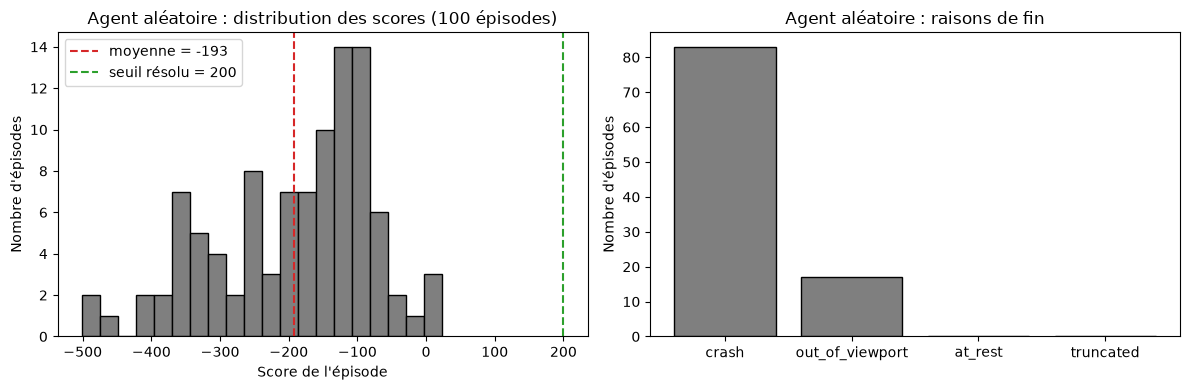

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rewards = [log["reward"] for log in baseline_logs]
axes[0].hist(rewards, bins=20, color="tab:gray", edgecolor="black")
axes[0].axvline(np.mean(rewards), color="tab:red", linestyle="--", label=f"moyenne = {np.mean(rewards):.0f}")
axes[0].axvline(200, color="tab:green", linestyle="--", label="seuil résolu = 200")
axes[0].set_title("Agent aléatoire : distribution des scores (100 épisodes)")
axes[0].set_xlabel("Score de l'épisode")
axes[0].set_ylabel("Nombre d'épisodes")
axes[0].legend()

reasons = baseline_summary["end_reasons"]
axes[1].bar(list(reasons.keys()), list(reasons.values()), color="tab:gray", edgecolor="black")
axes[1].set_title("Agent aléatoire : raisons de fin")
axes[1].set_ylabel("Nombre d'épisodes")

plt.tight_layout()
plt.show()

**Lecture.** L'agent aléatoire se crashe presque toujours en quelques dizaines de steps, avec un score très négatif, et sort parfois du cadre. Il ne se pose jamais. C'est le plancher : la distance entre cette moyenne et 200 est ce que PPO doit apprendre.

## 6. Environnements vectorisés et autoreset

PPO apprend sur des *rollouts* : des lots de transitions collectées avec la politique courante. Faire tourner **plusieurs copies de l'environnement en parallèle** remplit ces lots plus vite et avec des situations plus variées (plusieurs épisodes à des stades différents dans le même lot).

Une copie qui finit son épisode doit repartir automatiquement : c'est l'**autoreset**. Gymnasium (≥ 1.1) propose deux modes :

| Mode | Ce qui se passe quand une copie finit | Conséquence pour PPO |
| --- | --- | --- |
| `NEXT_STEP` (par défaut) | le reset a lieu au step **suivant** : l'action envoyée à ce step est ignorée | une transition fantôme par fin d'épisode, à repérer et exclure du rollout |
| `SAME_STEP` | le reset a lieu **dans le même step** : on reçoit directement l'observation du nouvel épisode, et l'observation finale est dans `info["final_obs"]` | toutes les transitions sont valides ; l'observation finale reste disponible pour les épisodes tronqués |

**Choix : `SAME_STEP`.** Chaque step du rollout est une vraie transition, sans masque à gérer. Et pour un épisode **tronqué**, on dispose de l'observation finale pour estimer la valeur du futur : un épisode coupé par la limite de temps n'est pas réellement fini, la GAE doit en tenir compte.

La cellule ci-dessous le vérifie : au step où une copie finit, l'observation renvoyée est déjà celle du nouvel épisode, l'observation finale est dans `info`, et `get_end_reason` s'applique sans changement.

In [9]:
def make_vec_env(num_envs, seed):
    """Crée num_envs copies de LunarLander en parallèle, avec reset automatique dans le même step."""
    vec_env = gym.make_vec(
        ENV_ID,
        num_envs=num_envs,
        vectorization_mode="sync",
        vector_kwargs={"autoreset_mode": gym.vector.AutoresetMode.SAME_STEP},
    )
    vec_env.action_space.seed(seed)
    return vec_env


vec_env = make_vec_env(num_envs=8, seed=0)
obs, _ = vec_env.reset(seed=0)
print(f"Observations du lot : {obs.shape}  (num_envs, OBS_DIM)")

for step in range(1000):
    obs, rewards, terminated, truncated, info = vec_env.step(vec_env.action_space.sample())
    done = terminated | truncated
    if done.any():
        i = int(np.argmax(done))
        final_obs = info["final_obs"][i]
        reason = get_end_reason(final_obs, rewards[i], terminated[i], truncated[i])
        print(f"Step {step} : la copie {i} a fini ({reason}, reward finale {rewards[i]:.0f})")
        print(f"  x final (info['final_obs'])     = {final_obs[0]:+.3f}")
        print(f"  x renvoyé (déjà le nouvel épisode) = {obs[i][0]:+.3f}")
        break
vec_env.close()

Observations du lot : (8, 8)  (num_envs, OBS_DIM)
Step 65 : la copie 0 a fini (crash, reward finale -100)
  x final (info['final_obs'])     = +0.431
  x renvoyé (déjà le nouvel épisode) = -0.002


## 7. Suite

Prochaines sections : actor-critic, rollout storage, GAE, loss combinée, boucle d'entraînement, évaluation sur 100 épisodes, multi-seeds, expérience comparative, comparaison avec DQN.